# MobileNetV2 PTQ 경량화 4종 비교 (PC용)

교수님 경량화 자료 6장 **PTQ(Post-Training Quantization)** 를 그대로 따라갑니다.

| 모델 | 방식 | 특징 |
|---|---|---|
| fp32 | 변환만 (기준선, baseline) | 원본 그대로 |
| dynamic | Dynamic range | 적용이 쉽고 가중치 중심으로 줄임 |
| float16 | Float16 | GPU/NPU 환경에서 비교적 안전한 축소 |
| int8 | Full integer INT8 | 대표 데이터셋(보정 이미지)이 필요하지만 디바이스 친화적 |

- 커널: **.venv311 (Python 3.11)** / numpy 1.26.4 / tensorflow 2.14.1 (라즈베리파이 tflite-runtime 2.14.0과 같은 버전)
- 준비: 없음 (평가용 사진은 자동 다운로드, `images` 폴더 내 사진은 선택)
- 결과: `mobilenet_fp32/dynamic/float16/int8.tflite`, `labels.txt`, `ptq_result.csv`

## 1. 환경 확인

In [1]:
import sys, numpy as np, tensorflow as tf
print("python    ", sys.version.split()[0], " <- 3.11.x")
print("numpy     ", np.__version__, " <- 1.26.4")
print("tensorflow", tf.__version__, " <- 2.14.x")

python     3.11.9  <- 3.11.x
numpy      1.26.4  <- 1.26.4
tensorflow 2.14.1  <- 2.14.x


## 2. 평가/보정용 사진 자동 다운로드 (ImageNet-V2, 일상 물건만)
원래 ImageNet과 같은 방식으로 다시 모은 공개 테스트셋(클래스당 10장)에서 **카메라에 직접 보여줄 수 있는 일상 물건 23종**만 골라 씁니다. 정답 라벨이 있어서 진짜 정확도를 잴 수 있습니다.

- 처음 한 번만 약 1.2GB 다운로드 (몇 분 걸림), 필요한 23종만 `data/everyday`에 풀고 나머지는 안 씀
- 전처리는 라즈베리파이 앱(`object_cam.py`)과 똑같음: 가운데 정사각형 자르기 → 224x224 → RGB → 0~255 값 그대로

In [2]:
import glob, json, os, tarfile, time
import cv2
import matplotlib.pyplot as plt

SIZE = 224
EVERYDAY = ["coffee_mug", "water_bottle", "pop_bottle", "water_jug", "teapot",
            "computer_keyboard", "mouse", "laptop", "notebook", "remote_control",
            "cellular_telephone", "digital_watch", "analog_clock", "wall_clock", "ballpoint",
            "sunglasses", "backpack", "umbrella", "running_shoe", "toilet_tissue",
            "banana", "orange", "Granny_Smith"]

def preprocess(bgr):
    h, w = bgr.shape[:2]
    s = min(h, w)
    crop = bgr[(h - s) // 2:(h - s) // 2 + s, (w - s) // 2:(w - s) // 2 + s]
    return cv2.cvtColor(cv2.resize(crop, (SIZE, SIZE)), cv2.COLOR_BGR2RGB).astype(np.float32)

def read_image(path):
    return cv2.imdecode(np.fromfile(path, np.uint8), cv2.IMREAD_COLOR)   # 한글 경로도 읽히게

# ImageNet 클래스 이름 1000개 (라즈베리파이 앱이 쓰는 labels.txt 로 저장)
idx_path = tf.keras.utils.get_file("imagenet_class_index.json",
    "https://storage.googleapis.com/download.tensorflow.org/data/imagenet_class_index.json",
    cache_dir=".", cache_subdir="data")
class_index = json.load(open(idx_path))
raw = [class_index[str(i)][1] for i in range(1000)]
names = [n.replace("_", " ") for n in raw]
with open("labels.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(names))
targets = {raw.index(n): n for n in EVERYDAY if n in raw}
print(f"labels.txt 저장 / 일상 물건 {len(targets)}종:", ", ".join(names[i] for i in targets))

# ImageNet-V2 다운로드 후 필요한 클래스 폴더만 풀기 (이미 풀려 있으면 건너뜀)
out_dir = os.path.join("data", "everyday")
if len(glob.glob(os.path.join(out_dir, "*", "*"))) < len(targets) * 10:
    tar_path = tf.keras.utils.get_file("imagenetv2-matched-frequency.tar.gz",
        "https://huggingface.co/datasets/vaishaal/ImageNetV2/resolve/main/imagenetv2-matched-frequency.tar.gz",
        cache_dir=".", cache_subdir="data")
    print("필요한 폴더만 압축 해제 중...")
    with tarfile.open(tar_path) as tar:
        for m in tar:
            parts = m.name.split("/")
            if m.isfile() and len(parts) >= 3 and parts[-2].isdigit() and int(parts[-2]) in targets:
                os.makedirs(os.path.join(out_dir, parts[-2]), exist_ok=True)
                with open(os.path.join(out_dir, parts[-2], parts[-1]), "wb") as f:
                    f.write(tar.extractfile(m).read())
    print("완료. (원하면 data\\imagenetv2-matched-frequency.tar.gz 는 지워도 됨)")

# 클래스마다 10장 중 6장은 평가, 4장은 INT8 보정 (서로 겹치지 않게)
test_x, test_y, calib_x = [], [], []
rng = np.random.default_rng(0)
for idx in targets:
    files = sorted(glob.glob(os.path.join(out_dir, str(idx), "*")))
    files = [files[i] for i in rng.permutation(len(files))]
    for k, p in enumerate(files):
        img = read_image(p)
        if img is None:
            continue
        (test_x if k < 6 else calib_x).append(preprocess(img))
        if k < 6:
            test_y.append(idx)
test_x, test_y, calib_x = np.array(test_x), np.array(test_y), np.array(calib_x)
print("평가", test_x.shape, " 보정", calib_x.shape)

# (선택) images 폴더에 내 사진이 있으면 보정 데이터에 추가 (실제 카메라 환경과 비슷하게)
my_paths = sorted(p for p in glob.glob("images/*") if p.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")))
my_x = np.array([preprocess(read_image(p)) for p in my_paths]) if my_paths else np.zeros((0, SIZE, SIZE, 3), np.float32)
if len(my_x):
    calib_x = np.concatenate([calib_x, my_x])
print(f"내 사진 {len(my_x)}장 (없어도 됨) -> 최종 보정 데이터 {len(calib_x)}장")

show = list(range(0, len(test_x), 6))[:12]
fig, axes = plt.subplots(1, len(show), figsize=(1.6 * len(show), 2.2))
for ax, i in zip(np.atleast_1d(axes), show):
    ax.imshow(test_x[i].astype(np.uint8)); ax.set_title(names[test_y[i]][:13], fontsize=8); ax.axis("off")
plt.show()

35363/35363 [==============================] - 0s 0us/step
labels.txt 저장 / 일상 물건 23종: coffee mug, water bottle, pop bottle, water jug, teapot, computer keyboard, mouse, laptop, notebook, remote control, cellular telephone, digital watch, analog clock, wall clock, ballpoint, sunglasses, backpack, umbrella, running shoe, toilet tissue, banana, orange, Granny Smith
1264079360/1264079360 [==============================] - 137s 0us/step
필요한 폴더만 압축 해제 중...
완료. (원하면 data\imagenetv2-matched-frequency.tar.gz 는 지워도 됨)
평가 (138, 224, 224, 3)  보정 (92, 224, 224, 3)
내 사진 0장 (없어도 됨) -> 최종 보정 데이터 92장


<Figure size 1920x220 with 12 Axes>

## 3. 사전학습 모델 불러오기 (학습 없음)
구글이 ImageNet 사진 약 120만 장으로 **이미 학습해 둔** MobileNetV2를 그대로 씁니다. 정규화(0~255 → -1~1)를 모델 안에 넣어서 라즈베리파이 코드가 단순해지게 했습니다.

In [3]:
inputs = tf.keras.Input((SIZE, SIZE, 3))
x = tf.keras.layers.Rescaling(1 / 127.5, offset=-1)(inputs)
base = tf.keras.applications.MobileNetV2(weights="imagenet", include_top=True)
model = tf.keras.Model(inputs, base(x))

ref = model.predict(test_x, verbose=0)
print(f"Keras 원본 정확도 ({len(test_x)}장): top-1 {(ref.argmax(1) == test_y).mean() * 100:.1f}%")
for p, im in zip(my_paths, my_x):
    pr = model.predict(im[None], verbose=0)[0]
    top = np.argsort(pr)[::-1][:3]
    print(f"[내 사진] {os.path.basename(p):<18}", ", ".join(f"{names[k]} {pr[k]*100:.0f}%" for k in top))

14536120/14536120 [==============================] - 2s 0us/step
Keras 원본 정확도 (138장): top-1 42.8%


## 4. INT8 보정 데이터 준비
Full integer INT8은 '실제로 들어올 사진'을 보여줘야 각 층의 값 범위를 재서 8비트로 정확히 줄일 수 있습니다. (모델을 다시 학습하는 게 아니라 범위만 측정)

In [4]:
def representative_data():
    for c in calib_x:
        yield [c[None]]
print("보정 데이터", calib_x.shape)

보정 데이터 (92, 224, 224, 3)


## 5. TFLite 변환 4종

In [5]:
def convert(kind):
    conv = tf.lite.TFLiteConverter.from_keras_model(model)
    if kind == "dynamic":
        conv.optimizations = [tf.lite.Optimize.DEFAULT]
    elif kind == "float16":
        conv.optimizations = [tf.lite.Optimize.DEFAULT]
        conv.target_spec.supported_types = [tf.float16]
    elif kind == "int8":
        conv.optimizations = [tf.lite.Optimize.DEFAULT]
        conv.representative_dataset = representative_data
        conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    return conv.convert()

KINDS = ["fp32", "dynamic", "float16", "int8"]
for k in KINDS:
    t0 = time.time()
    data = convert(k)
    with open(f"mobilenet_{k}.tflite", "wb") as f:
        f.write(data)
    print(f"mobilenet_{k}.tflite  {len(data)/1024/1024:6.2f} MB  ({time.time()-t0:.0f}s)")

INFO:tensorflow:Assets written to: C:\Users\rhehd\AppData\Local\Temp\tmpcdymg9np\assets


INFO:tensorflow:Assets written to: C:\Users\rhehd\AppData\Local\Temp\tmpcdymg9np\assets


mobilenet_fp32.tflite   13.34 MB  (31s)
INFO:tensorflow:Assets written to: C:\Users\rhehd\AppData\Local\Temp\tmptox6pqvp\assets


INFO:tensorflow:Assets written to: C:\Users\rhehd\AppData\Local\Temp\tmptox6pqvp\assets


mobilenet_dynamic.tflite    3.62 MB  (29s)
INFO:tensorflow:Assets written to: C:\Users\rhehd\AppData\Local\Temp\tmp9x_modzn\assets


INFO:tensorflow:Assets written to: C:\Users\rhehd\AppData\Local\Temp\tmp9x_modzn\assets


mobilenet_float16.tflite    6.71 MB  (29s)
INFO:tensorflow:Assets written to: C:\Users\rhehd\AppData\Local\Temp\tmpivv5hunq\assets


INFO:tensorflow:Assets written to: C:\Users\rhehd\AppData\Local\Temp\tmpivv5hunq\assets
c:\ondevice-object-cam\ondevice-object-cam\.venv311\Lib\site-packages\tensorflow\lite\python\convert.py:947: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


mobilenet_int8.tflite    3.81 MB  (43s)


## 6. 비교: 크기 / 속도 / 정확도
평가용 사진(정답 있음)으로 **진짜 정확도**와, 원본(fp32) 대비 **예측 일치율**을 같이 봅니다.

model     size(MB)   PC ms  top1(%)  top5(%)   fp32일치(%)
fp32         13.34    8.40     42.8     68.8       100.0
dynamic       3.62  829.41     40.6     70.3        88.4
float16       6.71    7.83     42.8     68.8        99.3
int8          3.81    9.31     39.1     70.3        84.8
saved ptq_result.csv


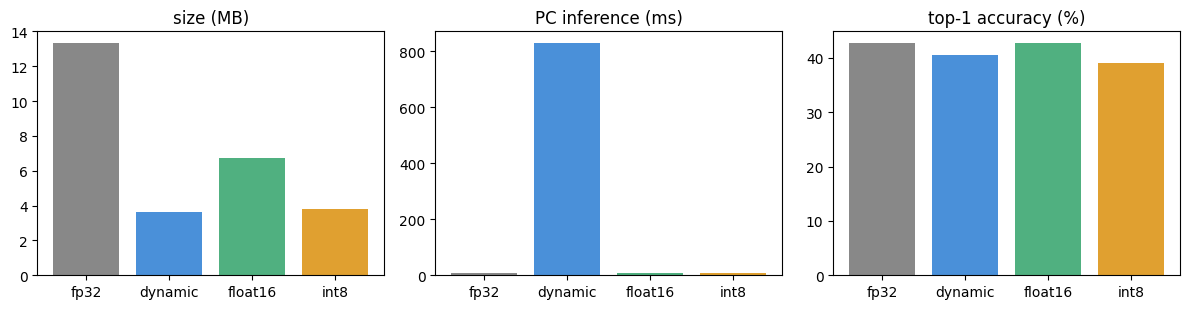

In [6]:
import csv

ref_top1 = ref.argmax(1)

def run_tflite(path, X):
    it = tf.lite.Interpreter(model_path=path, num_threads=4)
    it.allocate_tensors()
    inp, out = it.get_input_details()[0], it.get_output_details()[0]
    probs, t = [], 0.0
    for x in X:
        it.set_tensor(inp["index"], x[None].astype(inp["dtype"]))
        t0 = time.perf_counter(); it.invoke(); t += time.perf_counter() - t0
        probs.append(it.get_tensor(out["index"])[0].astype(np.float32))
    return np.array(probs), t / len(X) * 1000

rows = []
for k in KINDS:
    path = f"mobilenet_{k}.tflite"
    probs, ms = run_tflite(path, test_x)
    acc1 = (probs.argmax(1) == test_y).mean() * 100
    acc5 = np.mean([t in np.argsort(p)[::-1][:5] for t, p in zip(test_y, probs)]) * 100
    agree = (probs.argmax(1) == ref_top1).mean() * 100
    rows.append([k, os.path.getsize(path) / 1024 / 1024, ms, acc1, acc5, agree])

print(f"{'model':<9}{'size(MB)':>9}{'PC ms':>8}{'top1(%)':>9}{'top5(%)':>9}{'fp32일치(%)':>12}")
for r in rows:
    print(f"{r[0]:<9}{r[1]:>9.2f}{r[2]:>8.2f}{r[3]:>9.1f}{r[4]:>9.1f}{r[5]:>12.1f}")

with open("ptq_result.csv", "w", newline="", encoding="utf-8-sig") as f:
    w = csv.writer(f)
    w.writerow(["model", "size_mb", "ms_per_image_pc", "top1_acc_pct", "top5_acc_pct", "agree_with_fp32_pct"])
    w.writerows([[r[0], f"{r[1]:.2f}", f"{r[2]:.2f}", f"{r[3]:.1f}", f"{r[4]:.1f}", f"{r[5]:.1f}"] for r in rows])
print("saved ptq_result.csv")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, col, title in zip(axes, [1, 2, 3], ["size (MB)", "PC inference (ms)", "top-1 accuracy (%)"]):
    ax.bar([r[0] for r in rows], [r[col] for r in rows], color=["#888", "#4a90d9", "#50b080", "#e0a030"])
    ax.set_title(title)
plt.tight_layout(); plt.savefig("ptq_result.png", dpi=120); plt.show()

## 7. 예시 비교 (fp32 vs int8)

In [7]:
p32, _ = run_tflite("mobilenet_fp32.tflite", test_x[::6])
p8, _ = run_tflite("mobilenet_int8.tflite", test_x[::6])
for t, a, b in zip(test_y[::6], p32.argmax(1), p8.argmax(1)):
    print(f"정답 {names[t]:<20} fp32 {names[a]:<20} int8 {names[b]:<20} {'같음' if a == b else '다름'}")
cv2.imwrite("sample.jpg", cv2.cvtColor(test_x[0].astype(np.uint8), cv2.COLOR_RGB2BGR))
print("데모/벤치마크용 sample.jpg 저장")

정답 coffee mug           fp32 strawberry           int8 strawberry           같음
정답 water bottle         fp32 ice lolly            int8 ice lolly            같음
정답 pop bottle           fp32 beer bottle          int8 beer bottle          같음
정답 water jug            fp32 water jug            int8 nipple               다름
정답 teapot               fp32 teapot               int8 teapot               같음
정답 computer keyboard    fp32 safe                 int8 safe                 같음
정답 mouse                fp32 saltshaker           int8 coffeepot            다름
정답 laptop               fp32 notebook             int8 notebook             같음
정답 notebook             fp32 notebook             int8 notebook             같음
정답 remote control       fp32 remote control       int8 remote control       같음
정답 cellular telephone   fp32 guillotine           int8 guillotine           같음
정답 digital watch        fp32 digital watch        int8 digital watch        같음
정답 analog clock         fp32 analog clock         in

## 완료
다음 단계: 터미널에서 데모 실행

```
python object_cam.py --source sample.jpg
python object_cam.py --bench sample.jpg
```

라즈베리파이로 보낼 파일: `object_cam.py`, `check_env.py`, `labels.txt`, `mobilenet_*.tflite` 4개